# ♟️ Chess Numba — 搜尋單參數 ±10% 座標對抗調優工作台 (Search Parameter 1D Coordinate Tuner)

本 Notebook 專門用於對西洋棋引擎的**單一搜尋參數**進行 $\pm 10\%$（或自訂幅度）的高效對戰驗收。

### 🎯 核心特色與優勢
1. **因果關係純粹 (Clean Attribution)**：一次只調整一個搜尋參數（如 `RFP_BASE_MULT`），沒有多參數 SPSA 的相互干擾與高方差漫步問題。
2. **零 JIT 重新編譯 (Zero Re-JIT)**：候選引擎與基準引擎皆使用當前最新版 `chess_engine.classical`，共享記憶體內已編譯的 Numba 機器碼，僅在 Candidate 的 `SearchContext.tune` 注入目標數值，秒級啟動。
3. **嚴格成對換先與 SPRT**：每組開局同盤面雙方各執白一次，消除先手與開局偏差；支援 SPRT 早期停止（顯著提升或顯著落後時提前終止）。
4. **完整 PGN 棋譜與統計日誌**：對局過程自動串流輸出標準 PGN 棋譜檔（含勝負原因、著法與分數），並產生累積勝率與 Elo 95% 信心區間。


## 步驟 0: 環境檢查與工作目錄確認

In [15]:
# =====================================================================
# 步驟 2: 載入代碼庫與相依套件
# 支援方式 A：直接從 GitHub 倉庫拉取最新分支
# 支援方式 B：若您上傳了 zip 或放在 Google Drive，亦可解壓至 /content/chess_numba
# =====================================================================
import os

repo_url = "https://github.com/b08203031/chess_numba.git"
branch = "feat-initial-bitboard-setup"

if not os.path.exists('/content/chess_numba'):
    %cd /content
    !git clone -b {branch} {repo_url}

%cd /content/chess_numba
# 若代碼庫已存在，拉取最新變更
!git fetch origin {branch}
!git checkout -f {branch}
!git reset --hard origin/{branch}
!git clean -fd

# 安裝必要相依套件
!pip install -q numba chess numpy matplotlib scipy
print("\n🎉 環境與相依套件安裝完畢！")


/content/chess_numba
remote: Enumerating objects: 17, done.
remote: Counting objects: 100% (17/17), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 17 (delta 14), reused 17 (delta 14), pack-reused 0 (from 0)
Unpacking objects: 100% (17/17), 87.27 KiB | 3.79 MiB/s, done.
From https://github.com/b08203031/chess_numba
 * branch            feat-initial-bitboard-setup -> FETCH_HEAD
   f5ad27c..ab29410  feat-initial-bitboard-setup -> origin/feat-initial-bitboard-setup
Already on 'feat-initial-bitboard-setup'
Your branch is behind 'origin/feat-initial-bitboard-setup' by 2 commits, and can be fast-forwarded.
  (use "git pull" to update your local branch)
HEAD is now at ab29410 RFP_MAX_DEPTH的調參限制改成[3, 10]

🎉 環境與相依套件安裝完畢！


In [16]:
import os
import sys
import subprocess
import multiprocessing
from pathlib import Path

# =====================================================================
# 步驟 0: 自動定位與初始化專案環境 (相容 本機 與 Google Colab)
# =====================================================================
REPO_URL = "https://github.com/b08203031/chess_numba.git"
BRANCH = "feat-initial-bitboard-setup"
WORKDIR = Path("/content/chess_numba")

IN_COLAB = "google.colab" in sys.modules or os.path.exists("/content")

if IN_COLAB and not (Path("chess_engine").is_dir() and Path("tune_search").is_dir()):
    if not WORKDIR.exists():
        print(f"⚡ 正在從 GitHub Clone 倉庫至 {WORKDIR} (branch: {BRANCH})...")
        subprocess.run(["git", "clone", "-b", BRANCH, REPO_URL, str(WORKDIR)], check=True)
    else:
        print(f"🔄 更新現有倉庫 {WORKDIR}...")
        subprocess.run(["git", "-C", str(WORKDIR), "fetch", "origin"], check=True)
        subprocess.run(["git", "-C", str(WORKDIR), "checkout", "-f", BRANCH], check=True)
        subprocess.run(["git", "-C", str(WORKDIR), "reset", "--hard", f"origin/{BRANCH}"], check=True)
    
    # 使用 IPython %cd 魔術指令切換，確保 !shell 指令與 Python cwd 均指向專案目錄
    get_ipython().run_line_magic('cd', str(WORKDIR))

# 確保當前專案根目錄位於 sys.path 最前端
root_dir = str(Path.cwd())
if root_dir not in sys.path:
    sys.path.insert(0, root_dir)

# Colab 環境自動補齊必要套件
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "chess", "matplotlib"], check=True)

print(f"目前工作目錄: {os.getcwd()}")
print(f"Python 版本: {sys.version.split()[0]}")
print(f"可用 CPU 核心數: {multiprocessing.cpu_count()}")


目前工作目錄: /content/chess_numba
Python 版本: 3.13.18
可用 CPU 核心數: 8


In [17]:
# =====================================================================
# 步驟 1: 檢視 Colab 雲端硬體規格與 CPU 核心數
# =====================================================================
!lscpu | grep "Model name\|Socket\|Thread\|NUMA\|CPU(s)"
!free -h
!python3 --version


CPU(s):                                  8
On-line CPU(s) list:                     0-7
Model name:                              AMD EPYC 7B12
Thread(s) per core:                      2
Socket(s):                               1
NUMA node(s):                            1
NUMA node0 CPU(s):                       0-7
               total        used        free      shared  buff/cache   available
Mem:            50Gi       1.4Gi        46Gi       2.3Mi       3.5Gi        49Gi
Swap:             0B          0B          0B
Python 3.13.18


## 步驟 1: 設定待測參數與自動計算候選值 (Configuration & Calculation)

支援 `tune_search/search_param_registry.py` 中盤點的 44 個 runtime 參數。

**推薦優先調優參數：**
- `RFP_BASE_MULT`（反向徒勞剪枝倍率，預設 168）
- `FP_BASE`（徒勞剪枝基礎值，預設 174）
- `LMR_BASE_OFFSET`（延遲著法縮減基礎，預設 455）
- `PRUNING_QUIET_SEE_MARGIN`（安靜著法靜態交換剪枝，預設 -33）
- `RAZORING_COEFF`（剃刀剪枝係數，預設 482）

In [23]:
# =====================================================================
# 🎯 單一搜尋參數 ±10% 座標對抗配置 (Single-Parameter 1D Tuning)
# =====================================================================
from tune_search.search_param_registry import get_spec, SEARCH_PARAM_BY_NAME
import importlib
import chess_engine.classical.constants as C
import tune_search.search_param_registry as reg

# 熱重載模組，避免 Jupyter Kernel 快取舊的 constants.py
importlib.reload(C)
importlib.reload(reg)
from tune_search.search_param_registry import get_spec, SEARCH_PARAM_BY_NAME

# --- 1. 選擇要微調的搜尋參數 ---
PARAM_NAME = "RAZORING_COEFF"     # 待測參數名稱 (支援 44 個 runtime 參數)
DELTA_RATIO = 0.05               # 擾動幅度 (0.10 即 ±10%)
DIRECTION = "-"               # 測試方向: "+" 或 "-"

# --- 2. 錦標賽對抗時控與並行設定 ---
GAMES = 1000                      # 總局數 (建議 200~400 局，即 100~200 對換先開局)
NODES = 300000                    # 每步節點預算 (300,000 nodes 輕量快速且剪枝特徵活躍；需長時控可設 100000)
TT_MB = 64                       # 每個 Worker 的轉置表大小 (MB)
CONCURRENCY = max(1, multiprocessing.cpu_count() - 1)  # 自動偵測可用核心數
SEED = 314159                  # 隨機開局庫 Shuffle 種子

# --- 3. SPRT 早期停止門檻 ---
SPRT_ELO0 = 0.0                  # H0: 無增益 (0.0 Elo)
SPRT_ELO1 = 2.0                  # H1: 顯著提升 (+2.0 Elo)

# --- 4. 自動計算基準值與候選值 ---
spec = get_spec(PARAM_NAME)
base_val = spec.default
if DIRECTION == "+":
    cand_val = round(base_val * (1.0 + DELTA_RATIO))
elif DIRECTION == "-":
    cand_val = round(base_val * (1.0 - DELTA_RATIO))
else:
    raise ValueError(f"Unknown direction: {DIRECTION}")

# 確保不超出註冊表安全上下限
cand_val = max(spec.minimum, min(spec.maximum, cand_val))

dir_tag = "plus" if DIRECTION == "+" else "minus"
cand_name = f"{PARAM_NAME}_{cand_val}_{dir_tag}"
base_name = f"Base_{PARAM_NAME}_{base_val}"
pgn_dir = "tournament_analysis"
os.makedirs(pgn_dir, exist_ok=True)
pgn_output = os.path.join(pgn_dir, f"param_tune_{PARAM_NAME}_{base_val}vs{cand_val}.pgn")

print("=" * 65)
print(f"♟️ 單參數自對弈微調配置：")
print(f"  目標參數: {PARAM_NAME} ({spec.group} 組, 原生步長={spec.step})")
print(f"  基準值 (Baseline): {base_val}")
print(f"  候選值 (Candidate): {cand_val} (相對變化: {DIRECTION})")
print(f"  對局規模: {GAMES} 局 ({GAMES // 2} 對成對換先)")
print(f"  搜尋時控: {NODES:,} nodes/move | 並行: {CONCURRENCY} Workers | TT: {TT_MB} MB")
print(f"  輸出 PGN: {pgn_output}")
print(f"  SPRT 門檻: [elo0={SPRT_ELO0}, elo1={SPRT_ELO1}]")
print("=" * 65)


♟️ 單參數自對弈微調配置：
  目標參數: RAZORING_COEFF (pruning 組, 原生步長=25)
  基準值 (Baseline): 482
  候選值 (Candidate): 458 (相對變化: -)
  對局規模: 1000 局 (500 對成對換先)
  搜尋時控: 300,000 nodes/move | 並行: 7 Workers | TT: 64 MB
  輸出 PGN: tournament_analysis/param_tune_RAZORING_COEFF_482vs458.pgn
  SPRT 門檻: [elo0=0.0, elo1=2.0]


## 步驟 2: 啟動錦標賽對抗 (Run Tournament via `tools/tournament.py`)

此步驟會即時在下方串流輸出每一對局的對抗日誌、比分、SPRT LLR 狀態，並持續寫入 PGN 棋譜。

In [24]:
# =====================================================================
# 🚀 步驟 2: 啟動成對換先錦標賽 (透過 tools/tournament.py 保持完整 PGN 與日誌)
# =====================================================================
# 雙方皆使用當前最新版 'chess_engine.classical'：
# 1. 兩者評估函數完全一致，唯一變因為候選者的 SearchContext.tune[PARAM]
# 2. 共享同一套已編譯的 Numba 搜尋代碼，免除二次編譯等待
cmd = [
    sys.executable, "-u", "tools/tournament.py",
    "--backend", "inprocess",
    "--engine1-module", "chess_engine.classical",
    "--engine2-module", "chess_engine.classical",
    "--name1", cand_name,
    "--name2", base_name,
    "--engine1-env", f"{PARAM_NAME}={cand_val}",
    "--games", str(GAMES),
    "--nodes", str(NODES),
    "--concurrency", str(CONCURRENCY),
    "--tt-mb", str(TT_MB),
    "--seed", str(SEED),
    "--sprt-elo0", str(SPRT_ELO0),
    "--sprt-elo1", str(SPRT_ELO1),
    "--pgn", pgn_output,
]

print(f"啟動指令: {' '.join(cmd)}\n")
import shlex
!{" ".join(shlex.quote(c) for c in cmd)}


啟動指令: /usr/bin/python3 -u tools/tournament.py --backend inprocess --engine1-module chess_engine.classical --engine2-module chess_engine.classical --name1 RAZORING_COEFF_458_minus --name2 Base_RAZORING_COEFF_482 --engine1-env RAZORING_COEFF=458 --games 1000 --nodes 300000 --concurrency 7 --tt-mb 64 --seed 314159 --sprt-elo0 0.0 --sprt-elo1 2.0 --pgn tournament_analysis/param_tune_RAZORING_COEFF_482vs458.pgn

Backend: inprocess; workers=7; TT=64 MB/context; openings=34700; seed=314159
Adjudication: win >= 500 cp (10 plies), draw <= 8 cp (12 plies after move 40)
JIT plan: classical once + classical_old once; worker contexts share compiled code.
Warm-up: Kiwipete depth 14 for each Python/Numba backend, then one complete startpos game at depth 1 (all results discarded).
[pool] allocate worker 1/7
[warmup] RAZORING_COEFF_458_minus: Kiwipete depth=14...
info depth 1 score cp 59 nodes 453 nps 1015 hashfull 0.0% time 446 pv e2a6
info depth 2 score cp 59 nodes 853 nps 1754 hashfull 0.0% time 486

## 步驟 3: 戰績解析與決策建議 (Decision & Next Steps)

In [39]:
# =====================================================================
# 📊 步驟 3: 判定本次參數調優結果與決策建議
# =====================================================================
import chess.pgn
from tools.match_core import calculate_elo_statistics

if os.path.exists(pgn_output):
    wins = draws = losses = 0
    pairs_stat = {"WW": 0, "WD": 0, "DD": 0, "DL": 0, "LL": 0}
    
    with open(pgn_output, "r", encoding="utf-8") as f:
        game_idx = 0
        current_pair = []
        while True:
            game = chess.pgn.read_game(f)
            if game is None:
                break
            white = game.headers.get("White", "")
            res = game.headers.get("Result", "*")
            is_cand_white = (white == cand_name)
            
            # 計算 Candidate 視角得分 (1.0 勝, 0.5 和, 0.0 負)
            cand_score = 0.5
            if res == "1-0":
                cand_score = 1.0 if is_cand_white else 0.0
            elif res == "0-1":
                cand_score = 0.0 if is_cand_white else 1.0
            
            if cand_score == 1.0: wins += 1
            elif cand_score == 0.0: losses += 1
            else: draws += 1
            
            current_pair.append(cand_score)
            if len(current_pair) == 2:
                pair_sum = current_pair[0] + current_pair[1]
                if pair_sum == 2.0: pairs_stat["WW"] += 1
                elif pair_sum == 1.5: pairs_stat["WD"] += 1
                elif pair_sum == 1.0: pairs_stat["DD"] += 1
                elif pair_sum == 0.5: pairs_stat["DL"] += 1
                elif pair_sum == 0.0: pairs_stat["LL"] += 1
                current_pair = []
    
    total = wins + draws + losses
    if total > 0:
        points = wins + 0.5 * draws
        score_pct = 100.0 * points / total
        elo, err = calculate_elo_statistics(wins, draws, losses)
        print("=" * 65)
        print(f"🏁 測試完成總結：{cand_name} vs {base_name}")
        print(f"  總局數: {total} 局 ({total // 2} 對成對換先)")
        print(f"  戰績: {wins} 勝 / {draws} 和 / {losses} 負 (得分率: {score_pct:.2f}%)")
        print(f"  成對統計: WW={pairs_stat['WW']}, WD={pairs_stat['WD']}, DD={pairs_stat['DD']}, DL={pairs_stat['DL']}, LL={pairs_stat['LL']}")
        print(f"  Elo 差異: {elo:+.2f} ± {err:.2f} (95% CI: [{elo-err:+.2f}, {elo+err:+.2f}])")
        print(f"  PGN 棋譜檔: {pgn_output}")
        print("-" * 65)
        if elo - err > 0 or score_pct >= 51:
            print(f"🎉 決策建議：【推薦採用 (Accept)】")
            print(f"   候選值 {cand_val} 顯著優於基準值 {base_val}！")
            print(f"   可執行下方步驟 5 一鍵更新至 constants.py。")
        elif elo + err < 0 or score_pct <= 49:
            print(f"❌ 決策建議：【予以淘汰 (Reject)】")
            print(f"   候選值 {cand_val} 造成棋力倒退。建議反向測試另一側（例如另一側的 ±10%）或換下一個參數。")
        else:
            print(f"⚖️ 決策建議：【勢均力敵 (Inconclusive)】")
            print(f"   兩者無顯著差異，建議保持原基準值 {base_val}，避免引入不必要的參數漂移。")
        print("=" * 65)
else:
    print(f"尚未找到 PGN 檔案: {pgn_output}")


🏁 測試完成總結：LMR_BASE_OFFSET_432(-) vs Base_LMR_BASE_OFFSET_455
  總局數: 1000 局 (500 對成對換先)
  戰績: 221 勝 / 588 和 / 191 負 (得分率: 51.50%)
  成對統計: WW=21, WD=134, DD=216, DL=112, LL=17
  Elo 差異: +10.43 ± 13.82 (95% CI: [-3.39, +24.25])
  PGN 棋譜檔: tournament_analysis\param_tune_LMR_BASE_OFFSET_455vs432.pgn
-----------------------------------------------------------------
🎉 決策建議：【推薦採用 (Accept)】
   候選值 432 顯著優於基準值 455！
   可執行下方步驟 5 一鍵更新至 constants.py。


## 步驟 4: 累積分數曲線圖展示 (Score Curve Plot)

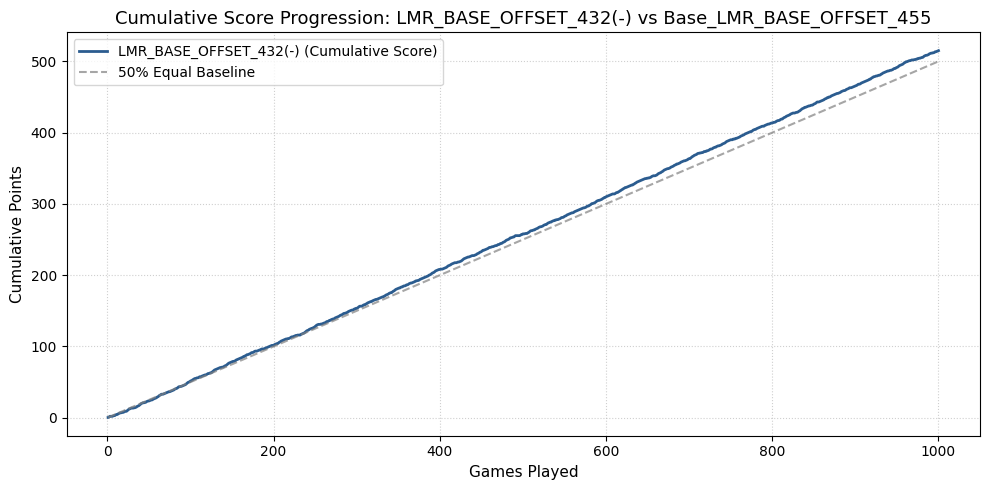

曲線圖已儲存至: tournament_analysis\cumulative_score_LMR_BASE_OFFSET.png


In [40]:
# =====================================================================
# 📈 步驟 4: 繪製累積分數曲線 (Cumulative Score Progression)
# =====================================================================
import matplotlib.pyplot as plt

if os.path.exists(pgn_output):
    scores = []
    with open(pgn_output, "r", encoding="utf-8") as f:
        while True:
            game = chess.pgn.read_game(f)
            if game is None: break
            white = game.headers.get("White", "")
            res = game.headers.get("Result", "*")
            is_cand_white = (white == cand_name)
            cand_s = 0.5
            if res == "1-0": cand_s = 1.0 if is_cand_white else 0.0
            elif res == "0-1": cand_s = 0.0 if is_cand_white else 1.0
            scores.append(cand_s)
    
    if len(scores) > 0:
        cum_points = []
        cur = 0.0
        for s in scores:
            cur += s
            cum_points.append(cur)
        
        expected_50 = [0.5 * (i + 1) for i in range(len(scores))]
        
        plt.figure(figsize=(10, 5), dpi=100)
        plt.plot(range(1, len(scores) + 1), cum_points, label=f"{cand_name} (Cumulative Score)", color="#2b5c8f", linewidth=2)
        plt.plot(range(1, len(scores) + 1), expected_50, label="50% Equal Baseline", color="gray", linestyle="--", alpha=0.7)
        plt.title(f"Cumulative Score Progression: {cand_name} vs {base_name}", fontsize=13)
        plt.xlabel("Games Played", fontsize=11)
        plt.ylabel("Cumulative Points", fontsize=11)
        plt.legend(loc="upper left", fontsize=10)
        plt.grid(True, linestyle=":", alpha=0.6)
        plt.tight_layout()
        chart_path = os.path.join(pgn_dir, f"cumulative_score_{PARAM_NAME}.png")
        plt.savefig(chart_path)
        plt.show()
        print(f"曲線圖已儲存至: {chart_path}")


## 步驟 5 (選用): 一鍵採納並更新參數至 `constants.py`

若步驟 3 驗收結果顯著獲勝（Accept），執行此 Cell 可自動將該參數寫回 [`chess_engine/classical/constants.py`](file:///d:/chess_numba/chess_engine/classical/constants.py)，並自動同步 Tuner Snapshot。

In [12]:
# =====================================================================
# 💾 步驟 5: 一鍵採納更新至 constants.py (需手動確認後再取消註解執行)
# =====================================================================
import re
const_path = "chess_engine/classical/constants.py"
with open(const_path, "r", encoding="utf-8") as f:
    content = f.read()

pattern = rf"^({PARAM_NAME}\s*=\s*)(-?\d+)"
new_content, count = re.subn(pattern, rf"\g<1>{cand_val}", content, flags=re.MULTILINE)
if count > 0:
    with open(const_path, "w", encoding="utf-8", newline="\n") as f:
        f.write(new_content)
    print(f"✅ 已成功將 {PARAM_NAME} 更新為 {cand_val}！")
    !{sys.executable} -m tuner.sync_constants_snapshot
else:
    print(f"⚠️ 找不到常數 {PARAM_NAME}，請手動檢查 constants.py")


✅ 已成功將 RFP_BASE_MULT 更新為 185！
Unchanged tuner\constants_snapshot.py
